# 05 — FPSim2 compatibility and paired top-k benchmarking
Consumes saved bits and one explicit completed RDKit run. No molecular fingerprints are generated. Exact float64 membership is a required gate; float32 native scores are diagnostic. See [methodology](../docs/fpsim2.md).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'src/chemtellect').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start JupyterLab within the repository.')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
from chemtellect.fpsim2_benchmark import run_comparison, load_comparison_run, CompatibilityFailure

## Explicit inputs
The authorized pilot is chemicalspace_new/package_00 with 100 queries and 1,000 indexed rows. All artifact, exact-run linkage, checksums and ordered identities are verified. A failed gate is persisted without comparative timing claims.

The explicit completed pilot is selected for read-only inspection by default. Set `EXISTING_COMPARISON_RUN = None` to create a new paired run; no automatic fallback occurs.

In [2]:
artifact_path = ROOT/'data/processed/chemicalspace_new/package_00/fingerprints/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427'
exact_run_path = ROOT/'experiments/results/exact_retrieval/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/run_1494eeec3c0f489c9b67f7352dc573b7'
INDEX_SIZE = 1000
EXPECTED_SELECTION = {'source': 'chemicalspace_new', 'package': 'package_00',
                      'query_count': 100, 'index_size': 1000}
# Explicit read-only inspection of the completed pilot; set None for a new paired run.
EXISTING_COMPARISON_RUN = ROOT/'experiments/results/fpsim2/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/run_a46310ed08c74b9492dbf38e96a638a9'

In [3]:
def present_comparison(directory, report):
    title = f"{report['source']}/{report['package']} — {report['index_size']:,} index rows"
    display(pd.Series({**report['settings'], 'queries': report['query_count'],
        'artifact': report['linkage']['artifact']['artifact_id'],
        'exact ground-truth run': report['linkage']['exact_run']['run_id']},
        name='Value').rename_axis('Protocol / provenance').to_frame())
    checks = report['compatibility']['checks'] if report['compatibility'] else []
    rows = []
    groups = [('Synthetic native integration', report['synthetic']['checks'] if report['synthetic'] else [])]
    groups += [(f'Top-k {k}', [c for c in checks if c['k'] == k]) for k in (10,25,50,100)]
    groups += [(f'Threshold ≥ {t}', [c for c in checks if c['threshold'] == t]) for t in (.3,.5,.7,.9)]
    for label, group in groups:
        rows.append({'Compatibility check': label,
            'Status': ('PASS' if all(c['passed'] for c in group) else 'FAIL') if group else 'NOT RUN',
            'Queries': len({c['query_position'] for c in group}), 'Responses': len(group),
            'Returned records': sum(c['actual_count'] or 0 for c in group),
            'Expected records': sum(c['expected_count'] for c in group),
            'Membership discrepancies': sum(len(c['missing_positions'])+len(c['unexpected_positions']) for c in group),
            'Invalid / duplicate IDs': sum(len(c['invalid_ids'])+len(c['duplicate_ids']) for c in group),
            'Max native score error': max((c['maximum_native_score_error'] for c in group if c['maximum_native_score_error'] is not None), default='not applicable (no returned scores)')})
    display(pd.DataFrame(rows).set_index('Compatibility check'))
    display(pd.DataFrame([{'Preparation stage': k.replace('_',' '), 'Elapsed (ms)': v/1e6}
                          for k,v in report['timings_ns'].items()]).round(3))
    display(pd.DataFrame([{'Snapshot stage': s['stage'], 'UTC': s['sampled_utc'],
        'System total RAM (GiB)': s['system_ram_total_bytes']/2**30,
        'System available RAM (GiB)': s['system_ram_available_bytes']/2**30,
        'Process RSS (MiB)': s['process_rss_bytes']/2**20} for s in report['memory_snapshots']]).round(3))
    if not report['passed']:
        print('Required compatibility failed. Comparative timing/speedup claims are unavailable.')
        return []
    summaries = report['benchmark']['summaries']
    rows = []
    for k in (10,25,50,100):
        r = summaries['rdkit']['by_k'][str(k)]['across_query_medians_ns']
        f = summaries['fpsim2']['by_k'][str(k)]['across_query_medians_ns']
        rm, fm = r['retrieval_total_ns']['median']/1000, f['retrieval_total_ns']['median']/1000
        rows.append({'k': k, 'RDKit total median (µs)': rm, 'FPSim2 search median (µs)': f['native_search_ns']['median']/1000,
                     'FPSim2 normalization median (µs)': f['normalization_ns']['median']/1000,
                     'FPSim2 total median (µs)': fm,
                     'RDKit p95 of per-query median latency (µs)': r['retrieval_total_ns']['p95']/1000,
                     'FPSim2 p95 of per-query median latency (µs)': f['retrieval_total_ns']['p95']/1000,
                     'Time saved (µs)': rm-fm, 'Speedup (RDKit / FPSim2)': rm/fm})
    table = pd.DataFrame(rows).set_index('k'); display(table.round(3))
    changes = report['benchmark']['repeated_candidate_membership_changes']
    display(pd.DataFrame([{'Measured repetitions changing candidate membership': len(changes),
                          'Designated measured pass': 0, 'Repetitions pooled': False}]))
    figures = []
    fig, ax = plt.subplots(figsize=(8,4.5), layout='constrained')
    table[['RDKit total median (µs)', 'FPSim2 total median (µs)']].plot.bar(ax=ax, rot=0, color=['#386cb0','#ef8a32'])
    ax.set(title=f'Paired sequential in-memory retrieval\n{title}', xlabel='Independent top-k request',
           ylabel='Median of per-query median latency (µs)', ylim=(0,None))
    ax.legend(['RDKit', 'FPSim2 (search + normalization)']); ax.grid(axis='y',alpha=.25)
    figures.append(('paired_latency',fig))
    fig, ax = plt.subplots(figsize=(8,4.2), layout='constrained')
    ax.bar([str(k) for k in table.index], table['Speedup (RDKit / FPSim2)'], color='#5a9279')
    ax.axhline(1, color='#b33030', linestyle='--', label='1×: equal median latency')
    ax.set(title=f'Observed speedup from paired medians\n{title}', xlabel='Independent top-k request',
           ylabel='RDKit median / FPSim2 median (×)', ylim=(0,None))
    ax.grid(axis='y',alpha=.25); ax.legend()
    figures.append(('speedup',fig))
    names = []
    for stem, fig in figures:
        if directory is not None:
            for suffix in ('png','svg'):
                name = f'{stem}.{suffix}'; fig.savefig(directory/name); names.append(name)
        display(fig); plt.close(fig)
    return names

## Verify, prepare and compare
The shared nonzero guard scans all selected rows before backend preparation. Queries are prepared before timers. RDKit runs afresh beside FPSim2 (`n_workers=1`), sequentially, with identical seed-42 query permutations and alternating backend pass order. Primary latency includes result normalization; score/membership checks, threshold evaluation, plotting and writing are excluded and have no aggregate overhead timing. p95 means **p95 of per-query median latency**, with `method='linear'`.

,Value
Protocol / provenance,
candidate_counts,"[10, 25, 50, 100]"
concurrent_queries,1
measured_passes,5
memory,synchronous system RAM and process RSS snapsho...
n_workers,1
native_search_boundary,inherited FPSim2Engine.top_k including bounds/...
normalization,descending native score then original index po...
outside_timer_overhead,validation/evaluation excluded; no separate ag...
p95_definition,p95 of per-query median latency


,Status,Queries,Responses,Returned records,Expected records,Membership discrepancies,Invalid / duplicate IDs,Max native score error
Compatibility check,,,,,,,,
Synthetic native integration,PASS,2,16,592,592,0,0,0.0
Top-k 10,PASS,100,100,1000,1000,0,0,0.0
Top-k 25,PASS,100,100,2500,2500,0,0,0.0
Top-k 50,PASS,100,100,5000,5000,0,0,0.0
Top-k 100,PASS,100,100,10000,10000,0,0,0.0
Threshold ≥ 0.3,PASS,100,100,184,184,0,0,0.0
Threshold ≥ 0.5,PASS,100,100,1,1,0,0,0.0
Threshold ≥ 0.7,PASS,100,100,0,0,0,0,not applicable (no returned scores)
Threshold ≥ 0.9,PASS,100,100,0,0,0,0,not applicable (no returned scores)


,Preparation stage,Elapsed (ms)
0,exact run loading and complete verification,102.669
1,fpsim2 conversion database writing loading and...,392.929
2,full artifact loading integrity verification a...,9.153
3,rdkit reconstruction,351.451
4,real preflight compatibility,153.644
5,selected nonzero validation,0.363
6,selection metadata and split loading validation,3.925
7,synthetic preparation and compatibility,64.358


,Snapshot stage,UTC,System total RAM (GiB),System available RAM (GiB),Process RSS (MiB)
0,before_loading,2026-11-10T20:04:29.412775+00:00,15.038,9.746,185.824
1,verified_inputs_and_ground_truth,2026-11-10T20:04:29.528960+00:00,15.038,9.723,199.930
2,fpsim2_prepared,2026-11-10T20:04:30.009060+00:00,15.038,9.719,204.559
3,both_backends_prepared,2026-11-10T20:04:30.360770+00:00,15.038,9.717,204.559
4,after_gate_and_optional_benchmark,2026-11-10T20:04:32.678078+00:00,15.038,9.648,298.320


,RDKit total median (µs),FPSim2 search median (µs),FPSim2 normalization median (µs),FPSim2 total median (µs),RDKit p95 of per-query median latency (µs),FPSim2 p95 of per-query median latency (µs),Time saved (µs),Speedup (RDKit / FPSim2)
k,,,,,,,,
10,137.952,60.271,11.280,71.722,143.562,73.042,66.231,1.923
25,140.938,65.401,15.175,80.726,146.030,85.104,60.211,1.746
50,144.588,71.262,21.091,92.777,156.425,98.282,51.811,1.558
100,150.618,81.622,33.920,115.417,157.428,121.814,35.201,1.305


,Measured repetitions changing candidate membership,Designated measured pass,Repetitions pooled
0,0,0,False


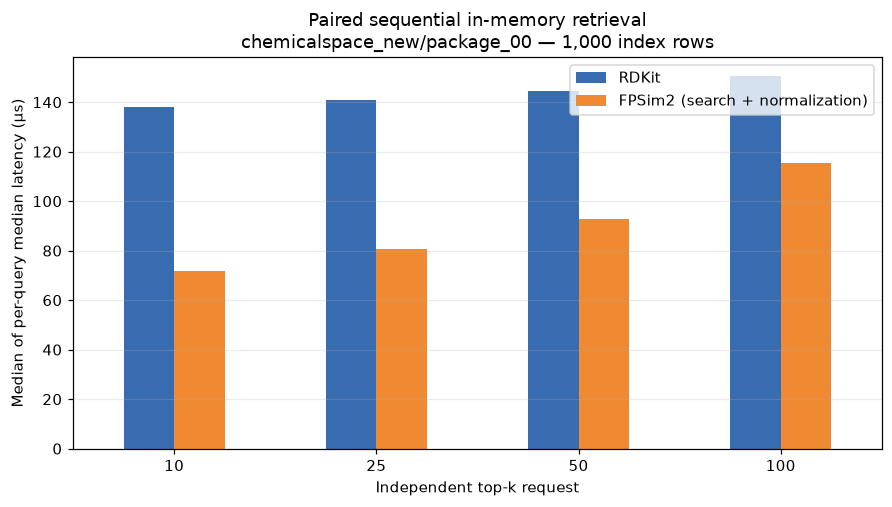

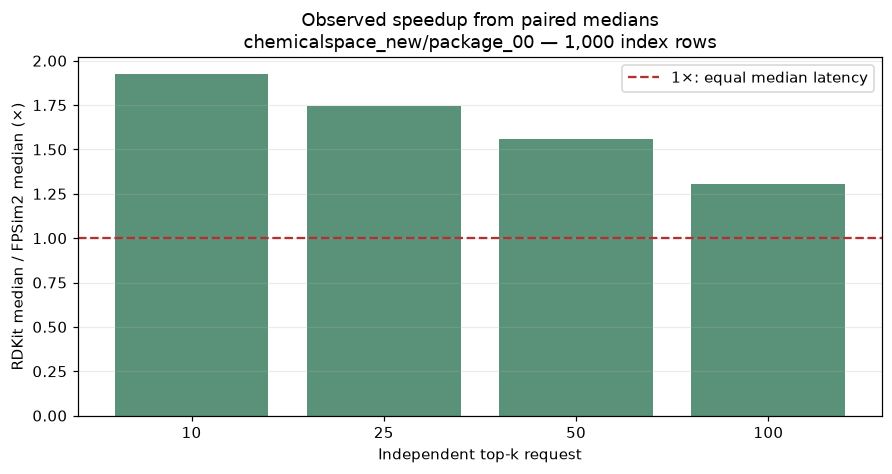

Verified paired run: experiments/results/fpsim2/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/run_a46310ed08c74b9492dbf38e96a638a9


In [4]:
if EXISTING_COMPARISON_RUN is None:
    try:
        run_path, report = run_comparison(ROOT, artifact_path, exact_run_path, INDEX_SIZE,
            expected_selection=EXPECTED_SELECTION, report_writer=present_comparison)
    except CompatibilityFailure as error:
        print('Preserved failed compatibility evidence:', error.report_path.relative_to(ROOT))
        raise
else:
    run_path = EXISTING_COMPARISON_RUN
    report = load_comparison_run(run_path, ROOT)
    if (report['linkage']['artifact']['artifact_path'] != str(artifact_path.relative_to(ROOT))
            or report['linkage']['exact_run']['path'] != str(exact_run_path.relative_to(ROOT))
            or {key: report[key] for key in EXPECTED_SELECTION} != EXPECTED_SELECTION):
        raise ValueError('Explicit report does not match the selected artifact/ground truth/counts')
    present_comparison(None, report)
print('Verified paired run:', run_path.relative_to(ROOT))

System available RAM and process RSS are separate synchronous snapshots, not true peak memory. There is no background polling during retrieval. Candidates from measured pass zero are reused for all threshold evaluations; repetitions are not pooled. Boundary-tied alternatives are valid when the exact top-k set conditions hold. These are 1K, repeated in-memory observations, with no cold-start, production-concurrency or 100M extrapolation. HNSW and cross-backend break-even analysis remain deferred.